In [1]:
# Giornate con noleggi anomali

# Importiamo le librerie per modello predittivo e grafico degli scarti.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from pathlib import Path

MUTED = '#647280'
REGISTERED = '#0072B2'
ACCENT = '#D55E00'
NEUTRAL = '#86939E'
DARK = '#253342'
plt.rcParams['figure.facecolor'] = '#F8F8F8'
plt.rcParams['axes.facecolor'] = '#F8F8F8'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# Prepariamo la cartella delle figure.
OUT=Path('../output/figures');OUT.mkdir(parents=True,exist_ok=True)

# Carichiamo i dati orari e ordiniamoli per data e ora.
hour=pd.read_csv('../data/processed/bike_hour_clean.csv',parse_dates=['dteday'])
hour=hour.sort_values(['dteday','hr'])

# Usiamo calendario e meteo come nel notebook di previsione.
features=['hr','weekday','workingday','holiday','mnth','yr',
          'weathersit','temp','hum','windspeed']

# Separiamo le giornate passate da quelle future per il test.
unique_days=np.sort(hour['dteday'].unique())
split_day=pd.Timestamp(unique_days[int(.80*len(unique_days))])
train=hour[hour['dteday']<split_day]
test=hour[hour['dteday']>=split_day].copy()

# Alleniamo Random Forest sul periodo iniziale e prevediamo il test.
model=RandomForestRegressor(n_estimators=160,min_samples_leaf=4,
                            max_features=.85,n_jobs=1,random_state=42)
model.fit(train[features],train['cnt'])
test['predicted']=model.predict(test[features])

# Sommiamo osservato e previsto per giorno, contando le ore disponibili.
daily_test=test.groupby('dteday').agg(
    observed=('cnt','sum'),predicted=('predicted','sum'),observed_hours=('hr','size'))

# Consideriamo solo giorni con tutte le 24 ore registrate.
daily_test=daily_test[daily_test['observed_hours']==24].copy()

# Calcoliamo lo scarto tra noleggi osservati e previsti.
daily_test['residual']=daily_test['observed']-daily_test['predicted']
daily_test['residual_pct']=100*daily_test['residual']/daily_test['predicted']

# Individuiamo le giornate estreme con il 5° e il 95° percentile.
low,high=daily_test['residual_pct'].quantile([.05,.95])
daily_test['flag']=np.where(daily_test['residual_pct']<=low,'Unusually low',
                     np.where(daily_test['residual_pct']>=high,'Unusually high','Typical'))

# Stampiamo le anomalie e le giornate escluse.
print('Out-of-time test starts:',split_day.date())
print('Valid full test days:',len(daily_test))
missing_test_days = test.groupby('dteday').size()
missing_test_days = missing_test_days[missing_test_days < 24]
print('Excluded test dates with fewer than 24 observed hours:')
print(missing_test_days.to_string())
print(f'Flag thresholds: lower {low:.1f}%, upper {high:.1f}% (empirical test percentiles)')
print('Lowest residual dates:')
display(daily_test.nsmallest(6,'residual_pct').round(1))
print('Highest residual dates:')
display(daily_test.nlargest(6,'residual_pct').round(1))

Out-of-time test starts: 2012-08-07
Valid full test days: 141
Excluded test dates with fewer than 24 observed hours:
dteday
2012-10-29     1
2012-10-30    11
2012-11-08    23
2012-11-29    23
2012-12-24    23
2012-12-25    23
Flag thresholds: lower -29.4%, upper 33.3% (empirical test percentiles)
Lowest residual dates:


,observed,predicted,observed_hours,residual,residual_pct,flag
dteday,,,,,,
2012-12-26,441,2641.6,24,-2200.6,-83.3,Unusually low
2012-11-22,2425,4869.5,24,-2444.5,-50.2,Unusually low
2012-12-29,1341,2531.4,24,-1190.4,-47.0,Unusually low
2012-12-23,1787,3206.2,24,-1419.2,-44.3,Unusually low
2012-12-22,1749,3014.3,24,-1265.3,-42.0,Unusually low
2012-12-27,2114,3585.7,24,-1471.7,-41.0,Unusually low


Highest residual dates:


,observed,predicted,observed_hours,residual,residual_pct,flag
dteday,,,,,,
2012-12-01,5191,3472.7,24,1718.3,49.5,Unusually high
2012-11-06,5686,3937.0,24,1749.0,44.4,Unusually high
2012-12-06,5375,3746.1,24,1628.9,43.5,Unusually high
2012-11-14,5495,4054.2,24,1440.8,35.5,Unusually high
2012-11-01,5986,4417.1,24,1568.9,35.5,Unusually high
2012-12-12,5319,3941.4,24,1377.6,35.0,Unusually high


26 Dec 2012: observed 441, predicted 2642, error -83.3%


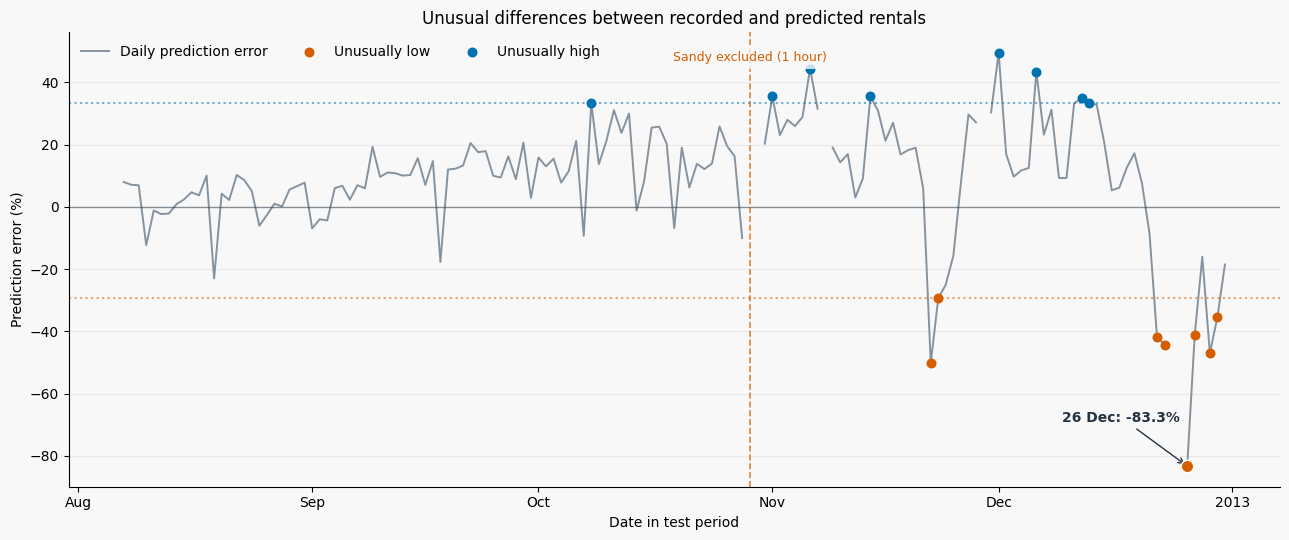

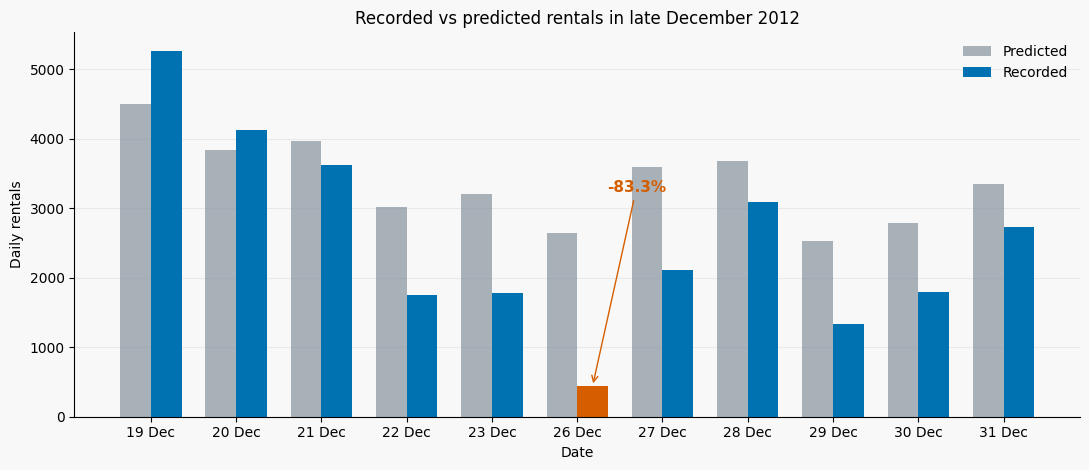

In [2]:
# Mostriamo gli scarti giornalieri senza collegare le date con ore mancanti.
fig, ax = plt.subplots(figsize=(13, 5.5))
all_dates = pd.date_range(daily_test.index.min(), daily_test.index.max(), freq='D')
line = daily_test['residual_pct'].reindex(all_dates)
ax.plot(line.index, line, color=NEUTRAL, lw=1.4, label='Daily prediction error')

# Evidenziamo le giornate con errori insolitamente alti o bassi.
for category, color in [('Unusually low', ACCENT), ('Unusually high', REGISTERED)]:
    selected = daily_test[daily_test['flag'] == category]
    ax.scatter(selected.index, selected['residual_pct'], s=38,
               color=color, label=category, zorder=3)
ax.axhline(0, color=DARK, lw=1, alpha=.5)
ax.axhline(low, color=ACCENT, ls=':', alpha=.55)
ax.axhline(high, color=REGISTERED, ls=':', alpha=.55)

# Sandy è escluso: la giornata ha una sola ora osservata.
sandy = pd.Timestamp('2012-10-29')
if sandy in test['dteday'].values and sandy not in daily_test.index:
    ax.axvline(sandy, color=ACCENT, ls='--', lw=1.2, alpha=.75)
    ax.text(sandy, 0.96, 'Sandy excluded (1 hour)', color=ACCENT,
            ha='center', va='top', fontsize=9,
            transform=ax.get_xaxis_transform(),
            bbox={'facecolor':'#F8F8F8','edgecolor':'none','alpha':0.8})

# Mettiamo in evidenza il 26 dicembre 2012.
dec26 = pd.Timestamp('2012-12-26')
if dec26 in daily_test.index:
    observed = daily_test.loc[dec26, 'observed']
    predicted = daily_test.loc[dec26, 'predicted']
    error = daily_test.loc[dec26, 'residual_pct']
    ax.scatter(dec26, error, s=80, color=ACCENT, edgecolor='white', zorder=5)
    ax.annotate(f'26 Dec: {error:.1f}%', xy=(dec26, error),
                xytext=(-90, 32), textcoords='offset points',
                fontsize=10, fontweight='bold', color=DARK,
                arrowprops={'arrowstyle':'->', 'color':DARK})
    print(f'26 Dec 2012: observed {observed:.0f}, predicted {predicted:.0f}, error {error:.1f}%')

# Completiamo gli assi e salviamo la serie temporale.
ax.set(title='Unusual differences between recorded and predicted rentals',
       xlabel='Date in test period',
       ylabel='Prediction error (%)')
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3)
import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=7))
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
ax.tick_params(axis='x', rotation=0)
fig.tight_layout()
fig.savefig(OUT/'RQ11A_demand_anomalies.png', dpi=200, bbox_inches='tight')
plt.show()

# Approfondiamo il periodo natalizio, confrontando noleggi osservati e previsti.
december = daily_test.loc['2012-12-19':'2012-12-31'].copy()
fig, ax = plt.subplots(figsize=(11, 4.8))
positions = np.arange(len(december))
width = 0.36
ax.bar(positions-width/2, december['predicted'], width,
       label='Predicted', color=NEUTRAL, alpha=0.7)
observed_colors = [ACCENT if date == dec26 else REGISTERED
                   for date in december.index]
ax.bar(positions+width/2, december['observed'], width,
       label='Recorded', color=observed_colors)
ax.set_xticks(positions)
ax.set_xticklabels([f'{date.day} Dec' for date in december.index])
ax.set(title='Recorded vs predicted rentals in late December 2012',
       xlabel='Date', ylabel='Daily rentals')
ax.grid(axis='y', alpha=.2)
ax.set_axisbelow(True)
ax.legend(frameon=False)
if dec26 in december.index:
    i = list(december.index).index(dec26)
    ax.annotate(f'{daily_test.loc[dec26,"residual_pct"]:.1f}%',
                xy=(i+width/2, daily_test.loc[dec26,'observed']),
                xytext=(i+0.35, december['predicted'].max()*.72),
                ha='left', color=ACCENT, fontsize=11, fontweight='bold',
                arrowprops={'arrowstyle':'->','color':ACCENT})
fig.tight_layout()
fig.savefig(OUT/'RQ11B_dec26_case_study.png', dpi=200, bbox_inches='tight')
plt.show()